In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU, ELU
from tensorflow.keras.utils import to_categorical

In [2]:
# -----------------------------
# Load Dataset
# -----------------------------
iris = load_iris()

X = iris.data
y = iris.target

In [3]:
# Normalization
scaler = StandardScaler()
X = scaler.fit_transform(X)

y = to_categorical(y)

In [4]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [5]:
# -----------------------------
# Manual Forward Propagation
# -----------------------------
print("Manual Forward Propagation")

sample = X_train[0]

W1 = np.random.randn(4,5)
b1 = np.random.randn(5)

Z1 = np.dot(sample,W1) + b1
A1 = np.maximum(0,Z1)

W2 = np.random.randn(5,3)
b2 = np.random.randn(3)

Z2 = np.dot(A1,W2)+b2

exp_val = np.exp(Z2)
output = exp_val/np.sum(exp_val)

print("Network Output:")
print(output)

Manual Forward Propagation
Network Output:
[9.97331397e-01 2.66738484e-03 1.21791110e-06]


In [6]:
# -----------------------------
# Function to create models
# -----------------------------
def create_model(activation):

    model = Sequential()

    if activation=="leakyrelu":
        model.add(Dense(10,input_shape=(4,)))
        model.add(LeakyReLU(alpha=0.01))

    elif activation=="elu":
        model.add(Dense(10,input_shape=(4,)))
        model.add(ELU(alpha=1.0))

    else:
        model.add(Dense(
            10,
            activation=activation,
            input_shape=(4,)
        ))

    model.add(Dense(
        3,
        activation='softmax'
    ))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


activations = [
    'sigmoid',
    'tanh',
    'relu',
    'leakyrelu',
    'elu'
]

results = {}

for act in activations:

    print(f"\nTraining with {act}")

    model = create_model(act)

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=100,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    results[act] = {
        'loss': loss,
        'accuracy': accuracy,
        'history': history
    }



Training with sigmoid


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training with tanh

Training with relu

Training with leakyrelu


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(



Training with elu


In [7]:
# -----------------------------
# Result Display
# -----------------------------
print("\nResults")

for act,data in results.items():

    print(
        f"{act} --> "
        f"Loss={data['loss']:.4f}, "
        f"Accuracy={data['accuracy']:.4f}"
    )


Results
sigmoid --> Loss=0.6541, Accuracy=0.8333
tanh --> Loss=0.3401, Accuracy=0.9333
relu --> Loss=0.4533, Accuracy=0.9333
leakyrelu --> Loss=0.4593, Accuracy=0.9333
elu --> Loss=0.2763, Accuracy=0.9667


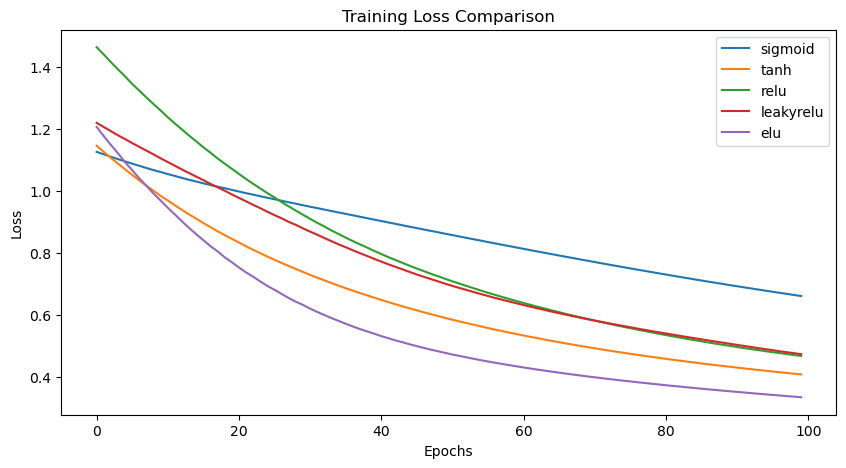

In [8]:
# -----------------------------
# Plot Training Loss
# -----------------------------
plt.figure(figsize=(10,5))

for act,data in results.items():

    plt.plot(
        data['history'].history['loss'],
        label=act
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

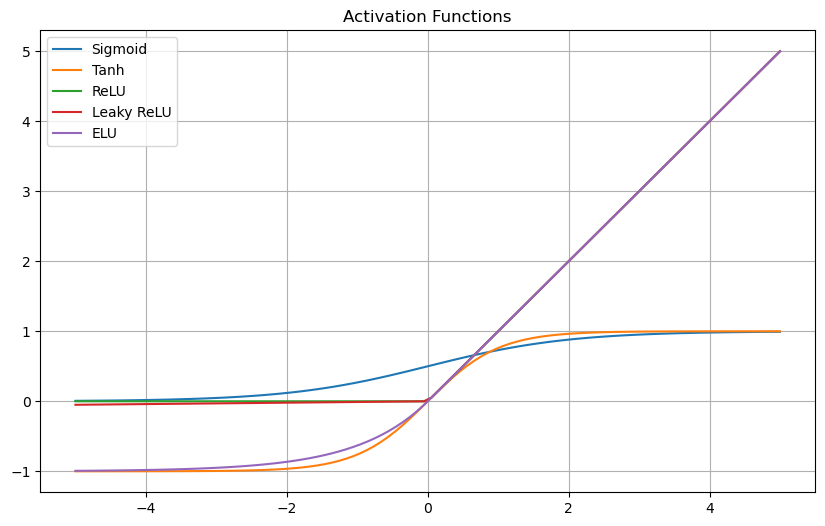

In [9]:
# -----------------------------
# Activation Functions Plot
# -----------------------------
x=np.linspace(-5,5,100)

sigmoid=1/(1+np.exp(-x))
tanh=np.tanh(x)
relu=np.maximum(0,x)
leaky=np.where(x>0,x,0.01*x)
elu=np.where(x>0,x,np.exp(x)-1)

plt.figure(figsize=(10,6))

plt.plot(x,sigmoid,label='Sigmoid')
plt.plot(x,tanh,label='Tanh')
plt.plot(x,relu,label='ReLU')
plt.plot(x,leaky,label='Leaky ReLU')
plt.plot(x,elu,label='ELU')

plt.title("Activation Functions")
plt.legend()
plt.grid(True)
plt.show()